# Criatura Lendária - Tiamat
Heloísa Fernandes Cano - T26

Entrega final de Aprendizado de Máquina

## Importando bibliotecas

In [803]:
import pandas as pd
import seaborn as sns
import statistics as st
import matplotlib.pyplot as plt

## Leitura do Arquivo de Dados

O primeiro passo é ler o arquivo `.xlsx` que vamos utilizar. Aqui, estamos lendo o arquivo direto do repositório do GitHub, sem necessidade de realizar o download dos dados [LER URL] [LER GITHUB].

In [804]:
from google.colab import drive
drive.mount('/content/drive')

df_original = pd.read_csv('/content/drive/My Drive/AVONET_Raw_Data.csv', encoding='latin-1')
df_original

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Avibase.ID,Species1_BirdLife,Species2_eBird,eBird.species.group,Species3_BirdTree,Data.type,Source,Specimen.number,Sex,Age,...,Beak.Depth,Tarsus.Length,Wing.Length,Kipps.Distance,Secondary1,Hand-wing.Index,Tail.Length,Measurer,Protocol,Publication
0,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,11.4.1890,F,0.0,...,2.0,7.1,45.0,30.0,15.0,66.7,27.0,NJTA,1.0,NaN
1,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,12.23.1890,F,0.0,...,1.5,8.0,45.0,31.0,14.0,68.9,30.0,NJTA,1.0,NaN
2,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,1913.3.20.972,M,0.0,...,1.8,7.2,47.0,31.0,16.0,66.0,29.0,NJTA,1.0,NaN
3,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,87.3.22.1574,M,0.0,...,1.7,4.5,47.0,30.0,17.0,63.8,30.0,NJTA,1.0,NaN
4,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,NaN,M,0.0,...,1.4,4.9,51.0,NaN,NaN,NaN,31.0,GT,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90366,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,UPLB,3428,F,0.0,...,4.1,21.4,66.1,11.4,54.7,17.2,50.5,CGM,1.0,NaN
90367,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,24.97.5.13.84,F,0.0,...,3.9,20.2,64.0,6.8,57.2,10.6,54.0,CV,1.0,NaN
90368,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,872.97.5.13.265,M,0.0,...,4.3,23.7,69.0,9.5,59.5,13.8,58.0,CV,1.0,NaN
90369,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,911.97.5.13.266,F,0.0,...,4.3,21.9,67.0,9.5,57.5,14.2,60.0,CV,1.0,NaN


In [805]:
colunas = df_original.columns

for coluna in colunas:
  print(coluna)

Avibase.ID
Species1_BirdLife
Species2_eBird
eBird.species.group
Species3_BirdTree
Data.type
Source
Specimen.number
Sex
Age
Locality
Country_WRI
Country
Beak.Length_Culmen
Beak.Length_Nares
Beak.Width
Beak.Depth
Tarsus.Length
Wing.Length
Kipps.Distance
Secondary1
Hand-wing.Index
Tail.Length
Measurer
Protocol
Publication


In [806]:
df_original.columns = [
    "avibaseID",
    "especie1_BirdLife",
    "especie2_eBird",
    "grupoEspecie_eBird",
    "especie3_BirdTree",

    "data_type",
    "source",
    "numero_individuo",
    "sexo",
    "idade",
    "localizacao",
    "paisWRI",
    "pais",

    "comprimento_bico_culmen",
    "comprimento_bico_nares",
    "largura_bico",
    "profundidade_bico",
    "comprimento_tarso",
    "comprimento_asa",
    "distancia_kipp",
    "comprimento_pena_secundaria",
    "indice_asa_mao",
    "comprimento_cauda",

    "medidor",
    "protocolo",
    "publicacao"
]

df_original

,avibaseID,especie1_BirdLife,especie2_eBird,grupoEspecie_eBird,especie3_BirdTree,data_type,source,numero_individuo,sexo,idade,...,profundidade_bico,comprimento_tarso,comprimento_asa,distancia_kipp,comprimento_pena_secundaria,indice_asa_mao,comprimento_cauda,medidor,protocolo,publicacao
0,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,11.4.1890,F,0.0,...,2.0,7.1,45.0,30.0,15.0,66.7,27.0,NJTA,1.0,NaN
1,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,12.23.1890,F,0.0,...,1.5,8.0,45.0,31.0,14.0,68.9,30.0,NJTA,1.0,NaN
2,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,1913.3.20.972,M,0.0,...,1.8,7.2,47.0,31.0,16.0,66.0,29.0,NJTA,1.0,NaN
3,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,87.3.22.1574,M,0.0,...,1.7,4.5,47.0,30.0,17.0,63.8,30.0,NJTA,1.0,NaN
4,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,NaN,M,0.0,...,1.4,4.9,51.0,NaN,NaN,NaN,31.0,GT,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90366,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,UPLB,3428,F,0.0,...,4.1,21.4,66.1,11.4,54.7,17.2,50.5,CGM,1.0,NaN
90367,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,24.97.5.13.84,F,0.0,...,3.9,20.2,64.0,6.8,57.2,10.6,54.0,CV,1.0,NaN
90368,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,872.97.5.13.265,M,0.0,...,4.3,23.7,69.0,9.5,59.5,13.8,58.0,CV,1.0,NaN
90369,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,911.97.5.13.266,F,0.0,...,4.3,21.9,67.0,9.5,57.5,14.2,60.0,CV,1.0,NaN


In [807]:
for coluna in df_original.columns:
  contagem = df_original[coluna].isna().sum()
  print("'"+coluna+"'", contagem)

'avibaseID' 1
'especie1_BirdLife' 338
'especie2_eBird' 366
'grupoEspecie_eBird' 182
'especie3_BirdTree' 68
'data_type' 351
'source' 358
'numero_individuo' 16578
'sexo' 351
'idade' 351
'localizacao' 90371
'paisWRI' 13126
'pais' 90371
'comprimento_bico_culmen' 16149
'comprimento_bico_nares' 34633
'largura_bico' 20047
'profundidade_bico' 15006
'comprimento_tarso' 9854
'comprimento_asa' 1096
'distancia_kipp' 27655
'comprimento_pena_secundaria' 26157
'indice_asa_mao' 27688
'comprimento_cauda' 6763
'medidor' 0
'protocolo' 351
'publicacao' 87062


In [808]:
colunas_REMOVIDAS = [
  'localizacao',
  'pais',
  'publicacao',
  'protocolo',
  'numero_individuo',
  'indice_asa_mao',
  'distancia_kipp',
  'comprimento_pena_secundaria'
]

df_novo = df_original.drop(columns = colunas_REMOVIDAS, axis = 1).dropna()
df_novo

,avibaseID,especie1_BirdLife,especie2_eBird,grupoEspecie_eBird,especie3_BirdTree,data_type,source,sexo,idade,paisWRI,comprimento_bico_culmen,comprimento_bico_nares,largura_bico,profundidade_bico,comprimento_tarso,comprimento_asa,comprimento_cauda,medidor
0,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,F,0.0,Guatemala,14.8,10.5,1.2,2.0,7.1,45.0,27.0,NJTA
1,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,F,0.0,Guatemala,13.8,9.5,1.0,1.5,8.0,45.0,30.0,NJTA
2,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,M,0.0,Guatemala,11.8,9.4,1.0,1.8,7.2,47.0,29.0,NJTA
3,AVIBASE-B3F5E5E2,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,Abeillia abeillei,1.0,NHMUK,M,0.0,Guatemala,11.8,8.6,1.0,1.7,4.5,47.0,30.0,NJTA
5,AVIBASE-684016CB,Abroscopus albogularis,Abroscopus albogularis,Abroscopus albogularis,Abroscopus albogularis,1.0,NHMUK,M,0.0,Laos,8.7,4.9,2.8,2.2,15.4,44.0,40.0,CS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90366,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,UPLB,F,0.0,Philippines,15.3,7.7,4.0,4.1,21.4,66.1,50.5,CGM
90367,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,F,0.0,Philippines,17.3,9.3,3.1,3.9,20.2,64.0,54.0,CV
90368,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,M,0.0,Philippines,18.9,10.6,3.4,4.3,23.7,69.0,58.0,CV
90369,AVIBASE-614141B3,Zosterornis whiteheadi,Zosterornis whiteheadi,Zosterornis whiteheadi,Stachyris whiteheadi,1.0,NHMUK,F,0.0,Philippines,17.2,9.8,3.5,4.3,21.9,67.0,60.0,CV


In [809]:
contagem = df_novo["especie1_BirdLife"].value_counts()
especies_desejadas = []

for item, quantidade in contagem.items():
  if quantidade > 50:
    print(item, quantidade)
    especies_desejadas.append(item)

Diglossa brunneiventris 101
Mionectes striaticollis 87
Cyanomitra olivacea 71
Eurillas virens 71
Atlapetes rufinucha 57
Elaenia pallatangae 55
Diglossa cyanea 54
Phyllastrephus cabanisi 51


In [810]:
df_filtrado = df_novo.copy()

logica = df_filtrado["especie1_BirdLife"].isin(especies_desejadas)
df_filtrado = df_filtrado[logica]

df_filtrado['comprimento_bico_culmen'] = pd.to_numeric(df_filtrado['comprimento_bico_culmen'], errors='coerce').fillna(0)
df_filtrado['comprimento_bico_nares'] = pd.to_numeric(df_filtrado['comprimento_bico_nares'], errors='coerce').fillna(0)
df_filtrado['largura_bico'] = pd.to_numeric(df_filtrado['largura_bico'], errors='coerce').fillna(0)
df_filtrado['profundidade_bico'] = pd.to_numeric(df_filtrado['profundidade_bico'], errors='coerce').fillna(0)
df_filtrado['comprimento_tarso'] = pd.to_numeric(df_filtrado['comprimento_tarso'], errors='coerce').fillna(0)
df_filtrado['comprimento_asa'] = pd.to_numeric(df_filtrado['comprimento_asa'], errors='coerce').fillna(0)
df_filtrado['comprimento_cauda'] = pd.to_numeric(df_filtrado['comprimento_cauda'], errors='coerce').fillna(0)

df_filtrado

,avibaseID,especie1_BirdLife,especie2_eBird,grupoEspecie_eBird,especie3_BirdTree,data_type,source,sexo,idade,paisWRI,comprimento_bico_culmen,comprimento_bico_nares,largura_bico,profundidade_bico,comprimento_tarso,comprimento_asa,comprimento_cauda,medidor
7824,AVIBASE-C9C868E0,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,2.0,Field1,U,0.0,Peru,16.6,9.4,4.3,5.5,26.1,68.0,74.0,BD
7825,AVIBASE-C9C868E0,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,2.0,Field1,U,0.0,Peru,14.7,8.9,4.2,5.6,26.1,75.0,80.0,SS
7826,AVIBASE-C9C868E0,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,2.0,Field1,U,0.0,Peru,14.4,8.6,4.8,6.0,27.9,72.0,78.5,ML
7827,AVIBASE-C9C868E0,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,2.0,Field1,M,0.0,Peru,15.0,9.2,5.5,5.7,27.1,80.0,83.0,ML
7828,AVIBASE-C9C868E0,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,Atlapetes rufinucha,2.0,Field1,F,0.0,Peru,16.6,9.4,5.4,6.1,27.6,70.0,77.0,ML
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62613,AVIBASE-24F71192,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,2.0,Field1,U,0.0,Zambia,17.5,11.2,4.2,4.7,24.0,80.0,84.0,MFZ
62614,AVIBASE-24F71192,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,2.0,Field1,U,0.0,Zambia,19.5,11.3,5.0,4.7,24.3,95.0,93.0,MFZ
62615,AVIBASE-24F71192,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,2.0,Field1,U,0.0,Zambia,17.9,11.0,4.4,5.2,23.1,87.0,91.0,MFZ
62616,AVIBASE-24F71192,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,Phyllastrephus cabanisi,2.0,Field1,U,0.0,Zambia,19.1,12.8,5.2,5.2,26.1,93.0,97.0,MFZ


## GRAFICOS

In [811]:
def dataframe_individual_especie(especie, dataframe = df_filtrado):
    """Cria um dataframe separado para uma espécie em específico, com base no dataframe original"""

    # copia e filtra o dataframe original
    novo_df = df_filtrado.copy()
    logica = df_filtrado["especie1_BirdLife"] == especie
    novo_df = novo_df[logica]

    # ajuste
    novo_df['comprimento_bico_culmen'] = pd.to_numeric(novo_df['comprimento_bico_culmen'], errors='coerce').fillna(0)
    novo_df['comprimento_bico_nares'] = pd.to_numeric(novo_df['comprimento_bico_nares'], errors='coerce').fillna(0)


    return novo_df

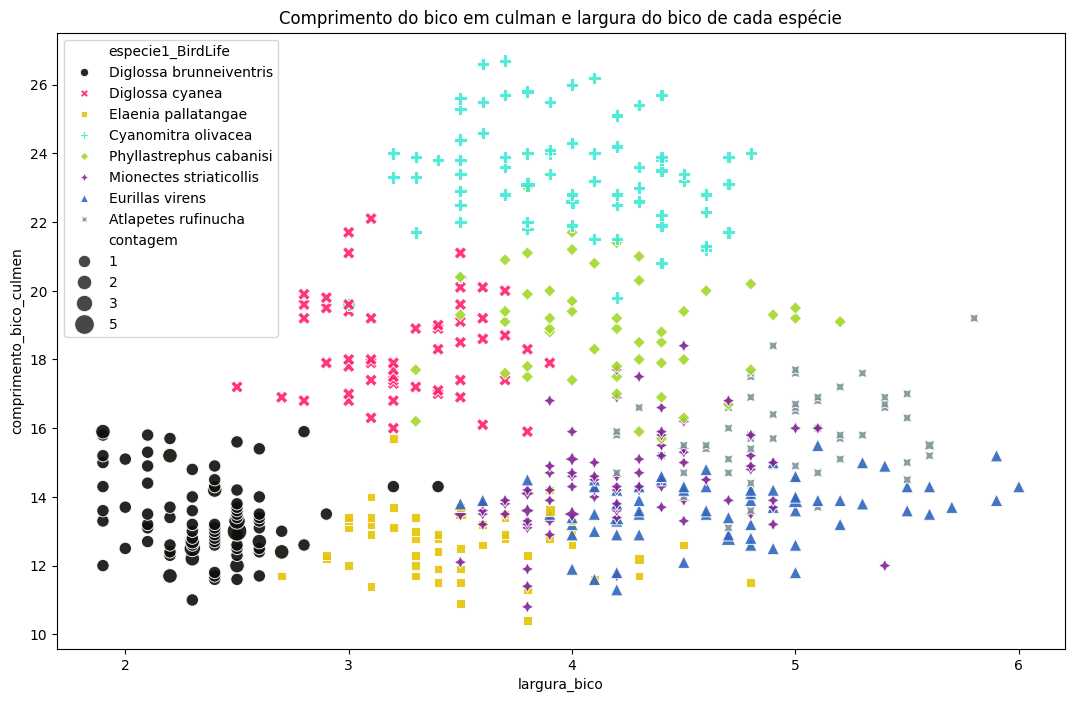

In [812]:
def plotar_grafico(dataframe, eixoX, eixoY, titulo, pos_legenda = 2):
  """Plota um gráfico scatterplot da distribuição entre o eixoX e o eixoY"""
  plt.figure(figsize=(13, 8))

  # conta os pontos de mesma posiçõa e especie, para apresentarmos a densidade dos pontos no gráfico
  contagens = (
      dataframe.groupby([eixoX, eixoY, 'especie1_BirdLife'])
      .size()
      .reset_index(name="contagem")
  )

  palette = ["#0C0F0A", "#FF206E", "#e6c407", "#41EAD4", "#A2D729", "#802392", "#3066BE", "#7C9299"]

  # plota o gráfico
  eixo = sns.scatterplot(
    data=contagens,
    x=eixoX,
    y=eixoY,
    hue= 'especie1_BirdLife',
    size="contagem",
    style="especie1_BirdLife",

    # https://stackoverflow.com/questions/59695334/custom-color-palette-in-seaborn
    palette=sns.color_palette(palette, len(palette)),
    sizes=(80, 200),
    alpha = 0.9
  )

  # Legendas e títulos
  eixo.set_title(titulo)
  eixo.set_xlabel(eixoX)
  eixo.set_ylabel(eixoY)

  # Ajusta a posição da legenda com base no parâmetro pos_legenda
  sns.move_legend(eixo, loc=pos_legenda)

plotar_grafico(df_filtrado, eixoX = "largura_bico", eixoY = "comprimento_bico_culmen", titulo = "Comprimento do bico em culman e largura do bico de cada espécie", pos_legenda = 2)

## Modelo baseline

In [813]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

SEMENTE_ALEATORIA = 1225
ATRIBUTOS = ['weight', 'hindfoot_length', 'plot_id', 'short_term_krat_exclosure', 'long_term_krat_exclosure', 'rodent_exclosure', 'spectab_exclosure']
TARGET = ["especie1_BirdLife"]

ordem_labels = df_filtrado[TARGET[0]].unique().tolist()

# faz a divisão dos dados de treino e dos dados de teste
from sklearn.model_selection import train_test_split

TAMANHO_TESTE = 0.1

indices = df_filtrado.index
indices_treino, indices_teste = train_test_split(
    indices, test_size=TAMANHO_TESTE, random_state=SEMENTE_ALEATORIA
)

df_treino = df_filtrado.loc[indices_treino]
df_teste = df_filtrado.loc[indices_teste]

X_treino = df_treino.reindex(ATRIBUTOS, axis=1).values
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1).values
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

Acurácia = 20.00%


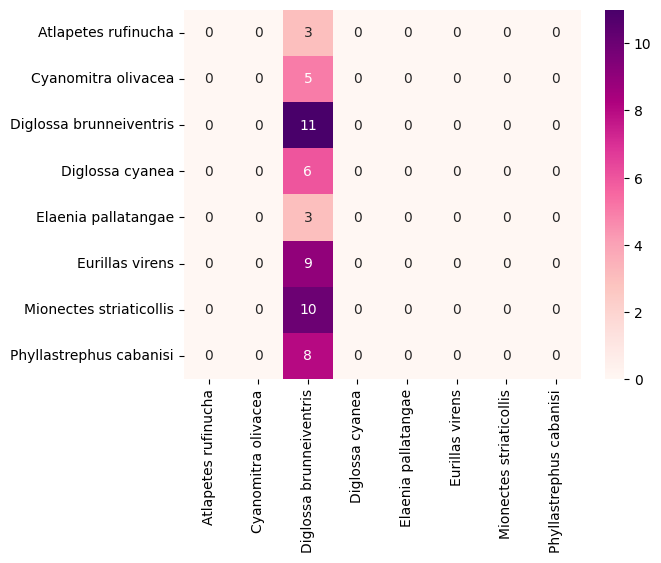

In [814]:
from sklearn.dummy import DummyClassifier

# determina o modelo
modelo_baseline = DummyClassifier()
modelo_baseline.fit(X_treino, y_treino)

# separa melhor os resultados reais do teste, e os dados que foram previstos pelo modelo
from sklearn.metrics import confusion_matrix
y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

# matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)
sns.heatmap(df_conf, annot=True, annot_kws={"size": 10}, fmt = "d", cmap = "RdPu");

# calcula acuracia
from sklearn.metrics import accuracy_score
acuracia = accuracy_score(y_verdadeiro, y_previsao)
print(f"Acurácia = {(acuracia*100):.2f}%")

## Referências

- [LER URL] - Stack Overflow, How to read a CSV file from a URL with Python?. Disponível em: https://stackoverflow.com/questions/16283799/how-to-read-a-csv-file-from-a-url-with-python
- [LER GITHUB] - Stack Overflow, How to read CSV file from GitHub using pandas. Disponível em: https://stackoverflow.com/questions/55240330/how-to-read-csv-file-from-github-using-pandas